# Consultas de negocio

Este notebook ejecuta contra el repositorio analítico las consultas de `sql/consultas/`, una por cada
pregunta de negocio del enunciado. Requiere que el DAG `datamart_etl` haya terminado al menos una vez.

In [1]:
import os
from pathlib import Path

import pandas as pd
from sqlalchemy import create_engine, text

pd.set_option("display.max_colwidth", 80)

# Las credenciales vienen de las variables de entorno del contenedor (.env.example / .env).
motor = create_engine(
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    "@postgres-dw:5432/datamart_dw"
)


def ejecutar_sql(archivo: str) -> list:
    """Ejecuta cada consulta de un archivo .sql y devuelve sus resultados como DataFrames."""
    contenido = Path(f"../sql/consultas/{archivo}").read_text(encoding="utf-8")
    consultas = [c for c in contenido.split(";") if "SELECT" in c.upper()]
    with motor.connect() as conexion:
        return [pd.read_sql(text(c), conexion) for c in consultas]

## Pregunta 1. Evolución mensual de las ventas netas

In [2]:
mensual = ejecutar_sql("01_evolucion_mensual_ventas_netas.sql")[0]
mensual

,mes,revenue_bruto,devoluciones,revenue_neto
0,2010-12,775572.23,17547.86,758024.37
1,2011-01,670361.99,91525.05,578836.94
2,2011-02,507783.42,8335.52,499447.90
3,2011-03,689708.49,10504.30,679204.19
4,2011-04,515354.78,33316.06,482038.72
5,2011-05,739914.35,8948.23,730966.12
6,2011-06,737558.98,13713.84,723845.14
7,2011-07,688144.79,11407.26,676737.53
8,2011-08,724196.76,22926.57,701270.19
9,2011-09,1028313.80,16980.64,1011333.16


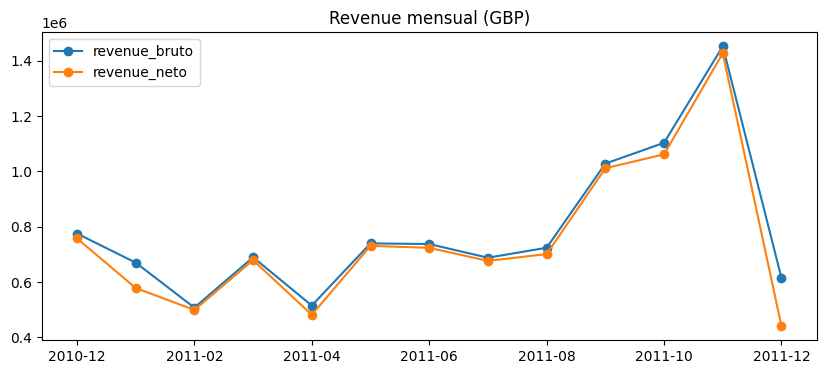

In [3]:
ax = mensual.plot(x="mes", y=["revenue_bruto", "revenue_neto"], marker="o", figsize=(10, 4),
                  title="Revenue mensual (GBP)")
ax.set_xlabel("");

Las ventas netas crecen desde septiembre de 2011 y alcanzan su máximo en noviembre (temporada navideña).
Diciembre de 2011 se ve bajo porque los datos solo llegan hasta el día 9 y porque ese mes tiene la mayor
cancelación del periodo.

## Pregunta 2. Revenue bruto y proporción de devoluciones por categoría

In [4]:
ejecutar_sql("02_categorias_revenue_y_devoluciones.sql")[0]

,categoria,revenue_bruto,monto_devuelto,pct_devoluciones
0,Hogar,7668065.28,267512.73,3.49
1,Ropa,1216700.22,21078.62,1.73
2,Papelería,1010587.74,179733.67,17.79
3,Electrónica,237266.28,6431.01,2.71
4,Deportes,114201.35,1145.13,1.00


## Pregunta 3. Top 10 productos por revenue neto y por tasa de devolución

In [5]:
ejecutar_sql("03a_top10_productos_revenue_neto.sql")[0]

,codigo_producto,nombre,categoria,revenue_neto
0,22423,REGENCY CAKESTAND 3 TIER,Hogar,164459.49
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,Hogar,99790.93
2,47566,PARTY BUNTING,Hogar,98243.88
3,85099B,JUMBO BAG RED RETROSPOT,Ropa,92175.79
4,23084,RABBIT NIGHT LIGHT,Hogar,66661.63
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,Papelería,63715.24
6,84879,ASSORTED COLOUR BIRD ORNAMENT,Hogar,58792.42
7,79321,CHILLI LIGHTS,Hogar,53746.66
8,22502,PICNIC BASKET WICKER SMALL,Hogar,51023.52
9,22197,POPCORN HOLDER,Hogar,50967.92


In [6]:
ejecutar_sql("03b_top10_productos_tasa_devolucion.sql")[0]

,codigo_producto,nombre,unidades_vendidas,unidades_devueltas,tasa_devolucion_pct
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,80995,100.00
1,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9461,9376,99.10
2,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,74494,95.46
3,85232B,SET OF 3 BABUSHKA STACKING TINS,274,255,93.07
4,23113,PANTRY CHOPPING BOARD,1154,946,81.98
5,85023B,EAU DE NILE JEWELLED PHOTOFRAME,105,73,69.52
6,23055,IVORY CHANDELIER T-LIGHT HOLDER,657,432,65.75
7,23056,FLOWERS CHANDELIER T-LIGHT HOLDER,963,579,60.12
8,23057,BEADED CHANDELIER T-LIGHT HOLDER,773,433,56.02
9,47566B,TEA TIME PARTY BUNTING,2578,1424,55.24


## Pregunta 4. Países: transacciones y ticket promedio

In [7]:
ejecutar_sql("04_paises_transacciones_ticket.sql")[0].head(15)

,pais,transacciones,pct_transacciones,revenue_bruto,ticket_promedio
0,United Kingdom,17901,90.53,8724045.22,487.35
1,Germany,443,2.24,205381.15,463.61
2,France,382,1.93,184493.00,482.97
3,EIRE,282,1.43,270850.86,960.46
4,Belgium,98,0.50,36927.34,376.81
5,Netherlands,93,0.47,283889.34,3052.57
6,Spain,88,0.45,55706.56,633.03
7,Australia,56,0.28,138103.81,2466.14
8,Portugal,50,0.25,26951.11,539.02
9,Switzerland,50,0.25,53065.60,1061.31


## Pregunta 5. Clientes identificados frente a transacciones sin customer ID

In [8]:
ejecutar_sql("05_clientes_identificados_vs_desconocidos.sql")[0]

,tipo_cliente,transacciones,revenue_bruto,ticket_promedio,lineas_por_factura,unidades_por_linea,precio_unitario_promedio
0,Identificado,18402,8737227.64,474.80,21.3,13.1,2.87
1,Sin customer ID,1371,1509593.23,1101.09,95.8,3.2,4.46


Las facturas sin customer ID son pocas, pero mucho más grandes: tienen más del doble de ticket promedio y
unas 4 veces más líneas por factura, con pocas unidades por línea. Parecen ventas de mostrador o pedidos
cargados de forma manual, no compras normales de la tienda en línea.

## Pregunta 6. Productos con descripción inconsistente y total de códigos únicos

In [9]:
inconsistentes, totales = ejecutar_sql("06_descripciones_inconsistentes.sql")
print(f"Productos con más de una descripción: {len(inconsistentes)}")
inconsistentes.head(10)

Productos con más de una descripción: 570


,codigo_producto,nombre_canonico,variantes_originales,variantes_en_mayusculas,descripciones
0,85175,CACTI T-LIGHT CANDLES,6,6,Amazon sold sets | CACTI T-LIGHT CANDLES | check | dotcom sold sets | ? sold...
1,21830,ASSORTED CREEPY CRAWLIES,5,5,"? | ASSORTED CREEPY CRAWLIES | MERCHANT CHANDLER CREDIT ERROR, STO | OOPS ! ..."
2,85172,HYACINTH BULB T-LIGHT CANDLES,5,5,check | Dotcom set | HYACINTH BULB T-LIGHT CANDLES | ?sold as sets? | wrongl...
3,22719,GUMBALL MONOCHROME COAT RACK,4,4,GUMBALL MONOCHROME COAT RACK | sold as 22467 | wrong barcode (22467) | wrong...
4,23131,MISTLETOE HEART WREATH CREAM,4,4,? | MISELTOE HEART WREATH CREAM | MISELTOE HEART WREATH WHITE | MISTLETOE HE...
5,23196,VINTAGE LEAF MAGNETIC NOTEPAD,4,4,LEAVES MAGNETIC SHOPPING LIST | RETO LEAVES MAGNETIC SHOPPING LIST | RETRO ...
6,23236,STORAGE TIN VINTAGE DOILY,4,4,DOILEY BISCUIT TIN | DOILEY STORAGE TIN | STORAGE TIN VINTAGE DOILEY | STORA...
7,23343,JUMBO BAG VINTAGE CHRISTMAS,4,4,20713 | 20713 wrongly marked | JUMBO BAG VINTAGE CHRISTMAS | wrongly coded 2...
8,46000S,POLYESTER FILLER PAD 40X40CM,4,3,Dotcom | dotcom sales | Dotcom sales | POLYESTER FILLER PAD 40x40cm
9,72807A,SET/3 ROSE CANDLE IN JEWELLED BOX,4,4,damages | ???missing | SET/3 ROSE CANDLE IN JEWELLED BOX | wet pallet


In [10]:
totales

,codigos_en_repositorio,codigos_en_todas_las_fuentes
0,3911,3958


## Pregunta 7. Recomendación para el equipo de producto

In [11]:
cancelaciones = ejecutar_sql("07_recomendacion_producto.sql")[0]
cancelaciones

,factura,fecha,codigo_producto,nombre,cantidad_devuelta,monto_devuelto,pct_del_total_devuelto,pct_acumulado
0,C581484,2011-12-09,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,35.40,35.40
1,C541433,2011-01-18,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,77183.60,16.22,51.62
2,C550456,2011-04-18,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,6539.40,1.37,52.99
3,C550456,2011-04-18,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1930,4921.50,1.03,54.03
4,C550456,2011-04-18,48185,DOORMAT FAIRY CAKE,670,4522.50,0.95,54.98
5,C567527,2011-09-21,23113,PANTRY CHOPPING BOARD,756,3825.36,0.80,55.78
6,C550456,2011-04-18,21175,GIN + TONIC DIET METAL SIGN,2000,3700.00,0.78,56.56
7,C550456,2011-04-18,47566B,TEA TIME PARTY BUNTING,1300,3315.00,0.70,57.25
8,C565044,2011-08-31,22191,IVORY DINER WALL CLOCK,318,2432.70,0.51,57.77
9,C570556,2011-10-11,22273,FELTCRAFT DOLL MOLLY,720,1836.00,0.39,58.15


**Recomendación:** validar los pedidos de volumen atípico antes de facturarlos.

- Solo **2 cancelaciones** (80.995 unidades de *PAPER CRAFT, LITTLE BIRDIE* y 74.215 de
  *MEDIUM CERAMIC TOP STORAGE JAR*) explican **más de la mitad** de todo el dinero cancelado del periodo.
- Las dos se facturaron y se cancelaron el mismo día, minutos después. Son errores de digitación o pedidos
  no confirmados, no devoluciones reales de clientes.
- Por eso Papelería aparece con la mayor proporción de devoluciones, y ambos productos encabezan la tasa de
  devolución (pregunta 3b).

Propuesta concreta: que el sistema pida una confirmación adicional cuando una línea supere un umbral
de unidades (por ejemplo, 10.000; en todo el periodo solo hay 2 líneas por encima de ese valor). Con
eso se evita casi el 52% del monto cancelado y los reportes de devoluciones por producto quedan limpios.